# 02 · Thực nghiệm bổ sung: nhiễu quan sát, dữ liệu thiếu, ràng buộc năng lực chặt

Notebook đọc các kết quả đã lưu trong `supplementary/results/*.json` (30 hạt giống mỗi cấu hình) và vẽ lại các kết luận chính của Mục 4.7 trong báo cáo.
Muốn chạy lại từ đầu: `python supplementary/run_rest.py B2` (nhiễu quan sát), `C` (dữ liệu thiếu), `G` (ràng buộc năng lực chặt; chậm do phép chiếu chính xác).

In [1]:
# --- setup: chạy được cả trên Colab lẫn máy cục bộ ---
import os, sys, subprocess
REPO_URL = "https://github.com/hieuthanhpham12/marl-vi-trade-crisis.git"
if not os.path.isdir("icta2026"):
    if os.path.isdir("../icta2026"):
        os.chdir("..")                                   # đang chạy trong notebooks/
    else:
        subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir("marl-vi-trade-crisis")
for sub in ("icta2026", "supplementary", "marl_baselines"):
    sys.path.insert(0, os.path.abspath(sub))
import numpy as np, pandas as pd, json
import matplotlib.pyplot as plt
print("thư mục làm việc:", os.getcwd())

thư mục làm việc: /content/marl-vi-trade-crisis


,mạng,obs_sigma,phát_hiện_đúng,báo_động_giả,RT_G50,G_cuối
0,3x3,0.01,1.000,0.433,144.767,4.169
1,3x3,0.10,1.000,0.800,144.767,4.166
2,3x3,0.50,0.800,2.967,147.700,3.284
3,3x3,1.00,0.167,11.300,147.167,1.257
4,3x3,2.00,0.033,14.567,126.700,1.025
5,4x4x3x2,0.01,1.000,0.600,50.800,1.767
6,4x4x3x2,0.10,1.000,0.667,50.800,1.765
7,4x4x3x2,0.50,1.000,1.000,50.767,1.720
8,4x4x3x2,1.00,1.000,1.033,50.567,1.652
9,4x4x3x2,2.00,1.000,1.200,50.467,0.894


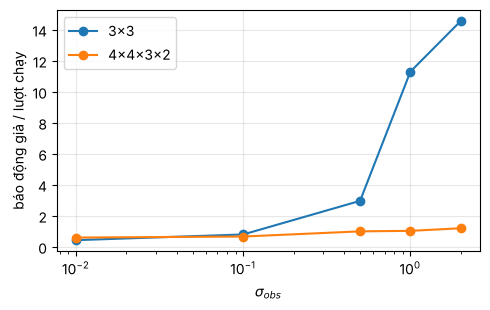

In [2]:
from summ import agg
def load(name): return json.load(open(f"supplementary/results/res_{name}.json"))
# --- B2: nhiễu quan sát -> báo động giả của bộ phát hiện ---
rows = []
for o in load("B2"):
    sp = o["spec"]
    if sp["method"] != "SR-PLR-MARL": continue
    a = agg(o); rows.append(dict(mạng="x".join(map(str, sp["net"][1:])), obs_sigma=sp["obs_sigma"], phát_hiện_đúng=a["det"], báo_động_giả=a["false"], RT_G50=a["g50_rt"], G_cuối=a["G"]))
df = pd.DataFrame(rows); display(df.round(3))
fig, ax = plt.subplots(figsize=(5, 3.2))
for net, g in df.groupby("mạng"): ax.plot(g.obs_sigma, g.báo_động_giả, "o-", label=net)
ax.set_xscale("log"); ax.set_xlabel(r"$\sigma_{obs}$"); ax.set_ylabel("báo động giả / lượt chạy"); ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [3]:
# --- C: dữ liệu thiếu (xác suất mất pi) ---
rows = []
for o in load("C"):
    sp = o["spec"]; a = agg(o)
    rows.append(dict(mạng="x".join(map(str, sp["net"][1:])), pi=sp["miss"], phương_pháp=sp["method"], Succ=a["g50_succ"], RT_G50=a["g50_rt"]))
d = pd.DataFrame(rows)
d[d.phương_pháp.isin(["SR-PLR-MARL", "Fixed-LR", "PG-fixed"])].pivot_table(index=["mạng", "pi"], columns="phương_pháp", values=["Succ", "RT_G50"]).round(2)

RT_G50                          Succ                     
phương_pháp Fixed-LR PG-fixed SR-PLR-MARL Fixed-LR PG-fixed SR-PLR-MARL
mạng    pi                                                             
3x3     0.1   121.43    13.20      165.70      1.0      1.0        1.00
        0.3   155.33    16.47      233.73      1.0      1.0        1.00
        0.5   217.33    22.33      390.80      1.0      1.0        0.83
        0.7   361.63    37.20      400.00      1.0      1.0        0.00
4x4x3x2 0.1    49.90     6.00       57.03      1.0      1.0        1.00
        0.3    64.10     7.13       76.03      1.0      1.0        1.00
        0.5    90.27     9.83      114.30      1.0      1.0        1.00
        0.7   151.23    15.90      227.63      1.0      1.0        1.00

In [4]:
# --- G: ràng buộc năng lực chặt -> G_impl không phải chứng chỉ nghiệm ---
rows = []
for o in load("G"):
    sp = o["spec"]; a = agg(o)
    if sp["method"] in ("PG-fixed", "SR-PLR-MARL"):
        rows.append(dict(eta=sp["shocks"][0][2], chiếu="chính xác" if sp.get("exact") else "cài đặt", phương_pháp=sp["method"], seeds=sp["seeds"],
                         sai_số_tới_x_star=a["relerr"], G_impl=a["G_impl"], G_exact=a["G_ex"]))
pd.DataFrame(rows).round(3)

,eta,chiếu,phương_pháp,seeds,sai_số_tới_x_star,G_impl,G_exact
0,0.5,cài đặt,SR-PLR-MARL,30,0.283,1.639,1.639
1,0.5,cài đặt,PG-fixed,30,0.004,0.011,0.011
2,0.5,chính xác,SR-PLR-MARL,8,0.287,1.593,1.593
3,0.5,chính xác,PG-fixed,8,0.004,0.011,0.011
4,0.3,cài đặt,SR-PLR-MARL,30,0.241,0.758,1.001
5,0.3,cài đặt,PG-fixed,30,0.219,0.010,0.560
6,0.3,chính xác,SR-PLR-MARL,8,0.281,1.845,0.585
7,0.3,chính xác,PG-fixed,8,0.004,1.810,0.008
8,0.2,cài đặt,SR-PLR-MARL,30,0.263,0.165,1.755
9,0.2,cài đặt,PG-fixed,30,0.263,0.011,1.750


Với $\eta\in\{0{,}3;0{,}2\}$ (năng lực chặt), PG dùng phép chiếu cài đặt có $G^{\rm impl}\approx0{,}01$ nhưng sai số tới nghiệm thật $\approx0{,}22$–$0{,}26$;
chỉ phép chiếu Euclide chính xác (Dykstra) mới đưa PG về nghiệm thật. Các lần chạy với phép chiếu chính xác dùng 8 hạt giống.